<a href="https://colab.research.google.com/github/RafayRizwan023/Deep_Learning_Labs_Raf023/blob/main/Lab_06_TransferLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import models, datasets, transforms
from PIL import Image
import matplotlib.pyplot as plt
from google.colab import files

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


# **Using the OxfordIIIpet dataset that is public an is much easier to work with as images can be easily used for testing**

In [ ]:
def load_data():
    mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

    train_tf = transforms.Compose([
        transforms.RandomResizedCrop(224),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(mean, std)])
    val_tf = transforms.Compose([
        transforms.Resize(256),
        transforms.CenterCrop(224),
        transforms.ToTensor(),
        transforms.Normalize(mean, std)])

    train_data = datasets.OxfordIIITPet("data", split="trainval", transform=train_tf, download=True)  #-------> The main dataset
    val_data = datasets.OxfordIIITPet("data", split="test", transform=val_tf, download=True)          #----------^

    train_loader = DataLoader(train_data, batch_size=32, shuffle=True, num_workers=2)
    val_loader = DataLoader(val_data, batch_size=32, num_workers=2)

    return train_loader, val_loader, train_data.classes, val_tf

train_loader, val_loader, class_names, val_tf = load_data()
print("number of types:", len(class_names))
print(class_names[:10])

100%|██████████| 792M/792M [00:29<00:00, 26.6MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 12.9MB/s]


number of types: 37
['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Bengal', 'Birman', 'Bombay', 'Boxer', 'British Shorthair']


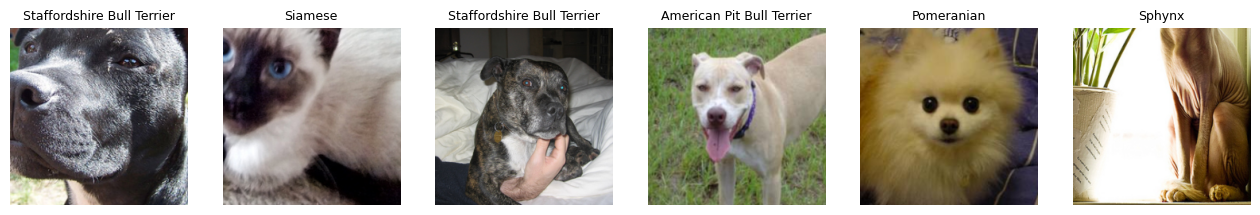

In [ ]:
def show_samples(loader, n=6):
    x, y = next(iter(loader))
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

    plt.figure(figsize=(16, 3.5))
    for i in range(n):
        img = (x[i] * std + mean).permute(1, 2, 0).clamp(0, 1)
        plt.subplot(1, n, i + 1)
        plt.imshow(img)
        plt.title(class_names[y[i]], fontsize=9)
        plt.axis("off")
    plt.show()

show_samples(train_loader)   #showing some sample from the dateset


# For ease i have made some fucntion to use for building and predicting the model and i had some trouble and some assistance was provided by AI and online documetation on uisng Pytorch

In [ ]:
def build_model(name, num_classes):    #------> building functon using the if else form to use differnet models within the build function
    if name == "alexnet":
        model = models.alexnet(weights=models.AlexNet_Weights.DEFAULT)
    elif name == "resnet50":
        model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    elif name == "resnet101":
        model = models.resnet101(weights=models.ResNet101_Weights.DEFAULT)
    elif name == "mobilenet":
        model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
    elif name == "vgg16":
        model = models.vgg16(weights=models.VGG16_Weights.DEFAULT)


    for p in model.parameters():
        p.requires_grad = False     #------> frezzing the lauyers


    if name in ("resnet50", "resnet101"):
        model.fc = nn.Linear(model.fc.in_features, num_classes)
    elif name == "mobilenet":
        model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
    elif name in ("vgg16", "alexnet"):
        model.classifier[6] = nn.Linear(model.classifier[6].in_features, num_classes)

    return model.to(device)

# We load a pretrained model, freeze its existing weights, replace the original classification layer with a new layer for our dataset, and train only the new classifier using transfer learning.a

In [ ]:
def train(model, epochs=5):
    loss_fn = nn.CrossEntropyLoss()
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(params, lr=0.001)
    history = []

    for epoch in range(epochs):
        model.train()
        # keep frozen BatchNorm layers fixed (ResNet / MobileNet)
        for m in model.modules():
            if isinstance(m, nn.BatchNorm2d):
                m.eval()

        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            loss = loss_fn(model(x), y)
            loss.backward()
            optimizer.step()

        model.eval()
        correct, total = 0, 0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                correct += (model(x).argmax(1) == y).sum().item()
                total += y.size(0)

        acc = correct / total
        history.append(acc)
        print(f"  epoch {epoch+1}/{epochs} - val acc: {acc:.3f}")

    return history

In [ ]:
results, trained = {}, {}
EPOCHS = 5

for name in ["alexnet", "resnet50", "resnet101", "mobilenet", "vgg16"]:
    print(f"\n=== {name} ===")
    start = time.time()
    m = build_model(name, len(class_names))
    hist = train(m, epochs=EPOCHS)
    results[name] = {"acc": hist[-1], "history": hist, "time": time.time() - start}
    trained[name] = m
    torch.cuda.empty_cache()


=== alexnet ===
Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 163MB/s]


  epoch 1/5 - val acc: 0.742
  epoch 2/5 - val acc: 0.745
  epoch 3/5 - val acc: 0.767
  epoch 4/5 - val acc: 0.748
  epoch 5/5 - val acc: 0.774

=== resnet50 ===
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 196MB/s]


  epoch 1/5 - val acc: 0.896
  epoch 2/5 - val acc: 0.909
  epoch 3/5 - val acc: 0.911
  epoch 4/5 - val acc: 0.916
  epoch 5/5 - val acc: 0.919

=== resnet101 ===
Downloading: "https://download.pytorch.org/models/resnet101-cd907fc2.pth" to /root/.cache/torch/hub/checkpoints/resnet101-cd907fc2.pth


...

  epoch 1/5 - val acc: 0.904
  epoch 2/5 - val acc: 0.917
  epoch 3/5 - val acc: 0.921
  epoch 4/5 - val acc: 0.922
  epoch 5/5 - val acc: 0.925

=== mobilenet ===
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 104MB/s] 


  epoch 1/5 - val acc: 0.874
  epoch 2/5 - val acc: 0.889
  epoch 3/5 - val acc: 0.893
  epoch 4/5 - val acc: 0.901
  epoch 5/5 - val acc: 0.907

=== vgg16 ===
Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:03<00:00, 162MB/s]


  epoch 1/5 - val acc: 0.889
  epoch 2/5 - val acc: 0.888
  epoch 3/5 - val acc: 0.894
  epoch 4/5 - val acc: 0.887
  epoch 5/5 - val acc: 0.898


# I used this code to compare pretrained models based on final validation accuracy, total parameters, and training time. I plotted validation accuracy across epochs and final accuracy to compare their performance, efficiency, and complexity.

Model        Final acc  Params (M)  Time (s)
alexnet      0.774      57.2        178
resnet50     0.919      23.6        204
resnet101    0.925      42.6        262
mobilenet    0.907      2.3         186
vgg16        0.898      134.4       264


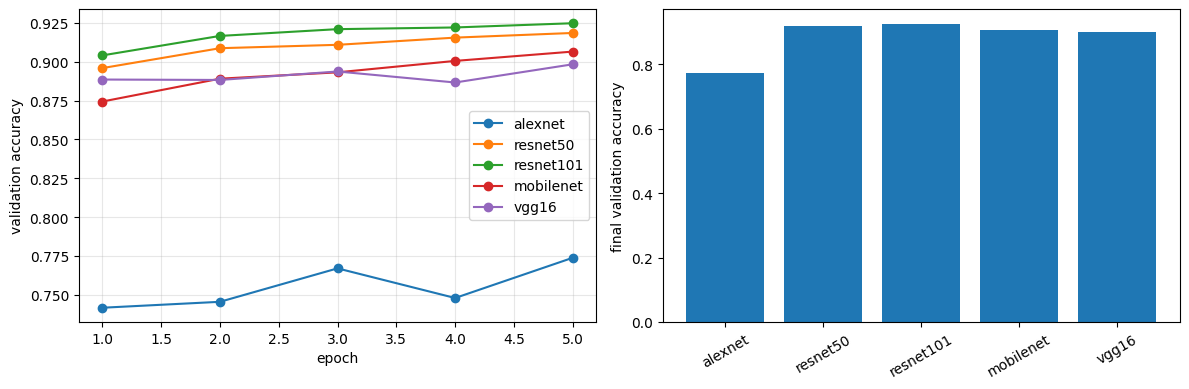

In [ ]:
print(f"{'Model':<12} {'Final acc':<10} {'Params (M)':<11} Time (s)")
for n, r in results.items():
    params_m = sum(p.numel() for p in trained[n].parameters()) / 1e6
    print(f"{n:<12} {r['acc']:<10.3f} {params_m:<11.1f} {r['time']:.0f}")

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
for n, r in results.items():
    plt.plot(range(1, EPOCHS + 1), r["history"], marker="o", label=n)
plt.xlabel("epoch"); plt.ylabel("validation accuracy"); plt.legend(); plt.grid(alpha=.3)

plt.subplot(1, 2, 2)
plt.bar(results.keys(), [r["acc"] for r in results.values()])
plt.ylabel("final validation accuracy"); plt.xticks(rotation=30)
plt.tight_layout(); plt.show()

In [ ]:
def predict_pet(model, image_path):
    model.eval()
    image = Image.open(image_path).convert("RGB")
    x = val_tf(image).unsqueeze(0).to(device)

    with torch.no_grad():
        probs = F.softmax(model(x), dim=1)[0]

    top_p, top_i = probs.topk(3)
    for p, i in zip(top_p, top_i):
        print(f"{class_names[i]}: {p.item()*100:.1f}%")

    plt.imshow(image)
    plt.axis("off")
    plt.show()

# Used a upload fuction and library to upload a custome image to check for resutls and preidction

Saving sHBA.jfif to sHBA.jfif
Shiba Inu: 99.8%
Pomeranian: 0.1%
Maine Coon: 0.0%


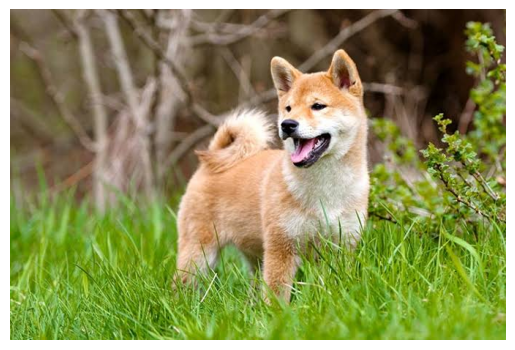

In [ ]:
up = files.upload()
img_path = list(up.keys())[0]

predict_pet(trained["alexnet"], img_path)   # change the name to test another model

Shiba Inu: 90.0%
Pomeranian: 4.2%
Chihuahua: 1.0%


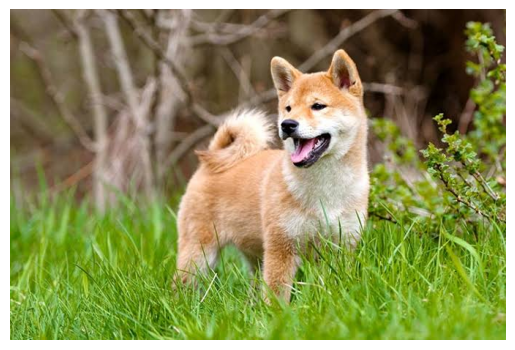

In [ ]:
predict_pet(trained["resnet50"], img_path)   # change the name to test another model

Shiba Inu: 80.3%
Pomeranian: 8.9%
Abyssinian: 2.5%


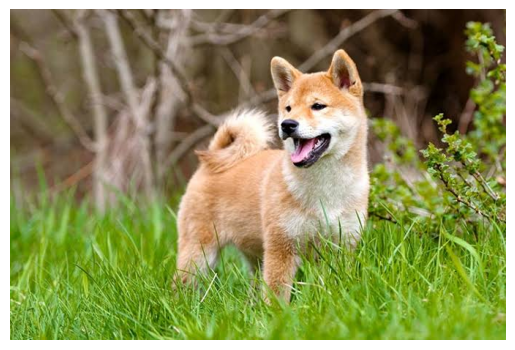

In [ ]:
predict_pet(trained["mobilenet"], img_path)   # change the name to test another model

Shiba Inu: 100.0%
Samoyed: 0.0%
Chihuahua: 0.0%


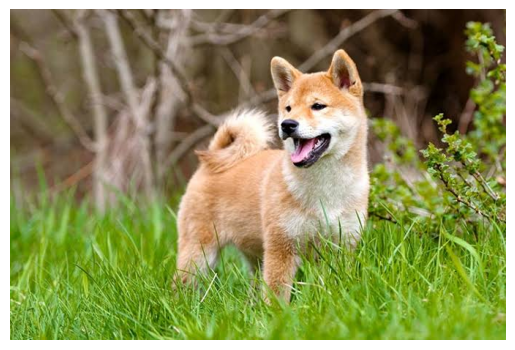

In [ ]:
predict_pet(trained["vgg16"], img_path)   # change the name to test another model

Shiba Inu: 93.2%
Pomeranian: 2.3%
Chihuahua: 1.5%


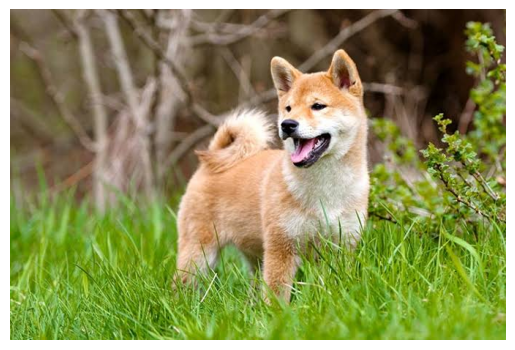

In [ ]:
predict_pet(trained["resnet101"], img_path)   # change the name to test another model

We can see that different pretrained models give different accuracies on the OxfordIIIPet dataset. Resnet101 gives the highest accuracy of 92.5%, followed by Resnet50 at 91.9% and mobilenetV2 at 90.6%. VGG16 gets 89.9%, while alexnet performs the worst with 77.4% accuracy.


Since we froze the pretrained layers and trained only the new classification layer, we can see how well the features learned by each model work on our dataset. Resnet performs better, probably because of its deeper architecture and residual connections. mobilenet also gives good accuracy with a more simple and efficent architecture, while AlexNet performs comparatively poorly. This shows that the choice of pretrained model affects the final accuracy.